# 00 — Public data acquisition

Fetches real pool/yield observations and reported exploit events from public DeFiLlama HTTP APIs. This is off-chain research data only: there are no RPC calls, wallets, contracts, transactions, or chain writes. Runs are bounded by `MAX_POOLS`; raw responses are cached under `code/data/raw/`.

In [6]:
from pathlib import Path
import json
import time
from urllib.parse import quote

import pandas as pd
import requests

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
RAW_DIR = CODE_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

MAX_POOLS = 600
MIN_TVL_USD = 1_000_000
REQUEST_DELAY_SECONDS = 0.25
OFFLINE_MODE = False
FORCE_REFRESH = False
MAX_REQUEST_ATTEMPTS = 3
API_ROOT = "https://yields.llama.fi"
HACKS_URL = "https://api.llama.fi/hacks"
HEADERS = {"User-Agent": "offline-defi-forensic-risk-prototype/1.0"}

In [7]:
def request_json(url: str):
    for attempt in range(MAX_REQUEST_ATTEMPTS):
        try:
            response = requests.get(url, headers=HEADERS, timeout=30)
            response.raise_for_status()
            return response.json()
        except requests.RequestException:
            if attempt == MAX_REQUEST_ATTEMPTS - 1:
                raise
            time.sleep(2 ** attempt)


def load_or_fetch_json(path: Path, url: str):
    if path.exists() and not FORCE_REFRESH:
        with path.open("r", encoding="utf-8") as file:
            return json.load(file)
    if OFFLINE_MODE:
        raise FileNotFoundError(f"Offline mode requires cached source file: {path}")
    payload = request_json(url)
    with path.open("w", encoding="utf-8") as file:
        json.dump(payload, file, ensure_ascii=False)
    return payload


catalog = load_or_fetch_json(RAW_DIR / "pool_catalog.json", f"{API_ROOT}/pools")
hacks = load_or_fetch_json(RAW_DIR / "hacks.json", HACKS_URL)
pool_rows = catalog.get("data", catalog) if isinstance(catalog, dict) else catalog
if not isinstance(pool_rows, list):
    raise ValueError("Unexpected pool catalog response: expected a list or a data list.")

pools = pd.DataFrame(pool_rows)
required = {"pool", "project", "tvlUsd"}
if not required.issubset(pools.columns):
    raise ValueError(f"Pool catalog is missing required columns: {sorted(required - set(pools.columns))}")
pools["tvlUsd"] = pd.to_numeric(pools["tvlUsd"], errors="coerce")
selected = (
    pools.dropna(subset=["pool", "project", "tvlUsd"])
    .loc[lambda frame: frame["tvlUsd"] >= MIN_TVL_USD]
    .sort_values("tvlUsd", ascending=False)
    .drop_duplicates("pool")
    .head(MAX_POOLS)
    .copy()
)
if selected.empty:
    raise ValueError("No pools passed the TVL filter; inspect the downloaded catalog or lower MIN_TVL_USD.")
selected.to_csv(RAW_DIR / "selected_pools.csv", index=False)
print(f"Selected {len(selected)} pools from {API_ROOT}/pools")
print(f"Hack source: {HACKS_URL}; payload type: {type(hacks).__name__}")

Selected 600 pools from https://yields.llama.fi/pools
Hack source: https://api.llama.fi/hacks; payload type: list


In [8]:
history_path = RAW_DIR / "yield_history.csv"
selected_pool_ids = set(selected["pool"].astype(str))
cached_history = pd.read_csv(history_path) if history_path.exists() and not FORCE_REFRESH else pd.DataFrame()
cached_pool_ids = set(cached_history["pool"].astype(str)) if "pool" in cached_history.columns else set()
missing_pool_ids = selected_pool_ids - cached_pool_ids
if OFFLINE_MODE and missing_pool_ids:
    raise FileNotFoundError(
        f"Offline mode is missing history for {len(missing_pool_ids)} selected pools. "
        "Use the cached pool selection or disable OFFLINE_MODE to fetch the missing history."
    )
if not missing_pool_ids:
    history = cached_history.loc[cached_history["pool"].astype(str).isin(selected_pool_ids)].copy()
else:
    history_rows = []
    missing_pools = selected.loc[selected["pool"].astype(str).isin(missing_pool_ids)]
    for row in missing_pools.itertuples(index=False):
        pool_id = str(getattr(row, "pool"))
        url = f"{API_ROOT}/chart/{quote(pool_id, safe='')}"
        payload = request_json(url)
        observations = payload.get("data", payload) if isinstance(payload, dict) else payload
        if not isinstance(observations, list):
            raise ValueError(f"Unexpected chart response for pool {pool_id!r}.")
        project = str(getattr(row, "project"))
        for observation in observations:
            if isinstance(observation, dict):
                history_rows.append({"pool": pool_id, "project": project, **observation})
        time.sleep(REQUEST_DELAY_SECONDS)

    fetched_history = pd.DataFrame(history_rows)
    if fetched_history.empty and cached_history.empty:
        raise ValueError("The selected pools returned no historical observations.")
    history = pd.concat([cached_history, fetched_history], ignore_index=True)
    history = history.loc[history["pool"].astype(str).isin(selected_pool_ids)]
    history = history.drop_duplicates(["pool", "timestamp"], keep="last")
    history.to_csv(history_path, index=False)
project_by_pool = selected.assign(pool=selected["pool"].astype(str)).set_index("pool")["project"]
history["project"] = history["pool"].astype(str).map(project_by_pool)
if history.empty:
    raise ValueError("No cached or fetched observations are available for the selected pools.")
print(f"Saved {len(history):,} historical observations for {history['pool'].nunique()} pools.")
print(f"Raw data directory: {RAW_DIR}")

Saved 305,519 historical observations for 600 pools.
Raw data directory: d:\python time\DeFi yield aggregator\attempt2\code\data\raw


Continue with `01_feature_and_label_building.ipynb`. Check the saved source files and protocol names before treating the labels as ground truth. Set `FORCE_REFRESH = True` above only when you want to make fresh API requests.

# 01 — Features and approximate labels

Builds pool-level rolling features and weak labels from public hack records. A match is accepted only when the normalized project/event names are identical or explicitly mapped in the reviewed alias table. Unmatched rows mean “no matched event in this feed,” not verified safe.

In [9]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
RAW_DIR = CODE_DIR / "data" / "raw"
PROCESSED_DIR = CODE_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
history_path = RAW_DIR / "yield_history.csv"
hacks_path = RAW_DIR / "hacks.json"
if not history_path.exists() or not hacks_path.exists():
    raise FileNotFoundError("Run 00_data_acquisition.ipynb first; raw history or hacks file is missing.")

LOOKAHEAD_DAYS = 7
# Add an alias only after reviewing the source event and confirming the protocol identity.
# Keys and values are normalized only for comparison; start with no fuzzy aliases.
EVENT_PROJECT_ALIASES = {}
history = pd.read_csv(history_path)
with hacks_path.open("r", encoding="utf-8") as file:
    hack_payload = json.load(file)

In [10]:
def parse_dates(values: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().mean() > 0.8:
        magnitude = numeric.dropna().abs().median()
        unit = "ms" if magnitude > 1e12 else "s"
        return pd.to_datetime(numeric, unit=unit, utc=True, errors="coerce")
    return pd.to_datetime(values, utc=True, errors="coerce")


if "timestamp" not in history or not {"pool", "project", "tvlUsd", "apy"}.issubset(history.columns):
    raise ValueError("Yield history must contain timestamp, pool, project, tvlUsd, and apy columns.")
history["timestamp"] = parse_dates(history["timestamp"])
for column in ("tvlUsd", "apy"):
    history[column] = pd.to_numeric(history[column], errors="coerce")
history = history.dropna(subset=["timestamp", "pool", "project", "tvlUsd", "apy"])
history = history.sort_values(["pool", "timestamp"]).drop_duplicates(["pool", "timestamp"], keep="last")

def event_records(payload):
    if isinstance(payload, list):
        return payload
    if isinstance(payload, dict):
        for key in ("hacks", "data", "events"):
            if isinstance(payload.get(key), list):
                return payload[key]
    raise ValueError("Unexpected hacks response shape; expected a list of event records.")


events = pd.DataFrame(event_records(hack_payload))
if events.empty:
    raise ValueError("The hack feed contains no event records.")
name_column = next((name for name in ("name", "protocol", "project") if name in events.columns), None)
date_column = next((name for name in ("date", "timestamp", "time") if name in events.columns), None)
if name_column is None or date_column is None:
    raise ValueError("Hack records need a protocol/name field and a date/timestamp field.")
events["event_name"] = events[name_column].astype(str)
events["event_time"] = parse_dates(events[date_column])
events = events.dropna(subset=["event_time"])

def normalize_name(value: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


projects = history["project"].dropna().astype(str).unique()
project_by_normalized_name = {normalize_name(project): project for project in projects}
aliases_by_normalized_name = {
    normalize_name(event_name): project
    for event_name, project in EVENT_PROJECT_ALIASES.items()
}
event_matches = []
for event_name, event_time in events[["event_name", "event_time"]].itertuples(index=False, name=None):
    normalized_event_name = normalize_name(event_name)
    project = aliases_by_normalized_name.get(normalized_event_name)
    match_method = "reviewed alias" if project is not None else "normalized exact name"
    if project is None:
        project = project_by_normalized_name.get(normalized_event_name)
    if project is not None:
        event_id = f"{project}|{event_time.isoformat()}|{normalized_event_name}"
        event_matches.append((project, event_name, event_time, event_id, match_method))
matches = pd.DataFrame(
    event_matches,
    columns=["project", "event_name", "event_time", "event_id", "match_method"],
)
if matches.empty:
    matches = pd.DataFrame(columns=["project", "event_name", "event_time", "event_id", "match_method"])
print(f"Events in feed: {len(events):,}; exact/reviewed project matches: {len(matches):,}")
display(matches.head(20))

Events in feed: 1,320; exact/reviewed project matches: 29


,project,event_name,event_time,event_id,match_method
0,ankr,Ankr,2022-12-02 00:00:00+00:00,ankr|2022-12-02T00:00:00+00:00|ankr,normalized exact name
1,resupply,Resupply,2025-06-25 00:00:00+00:00,resupply|2025-06-25T00:00:00+00:00|resupply,normalized exact name
2,venus-core-pool,Venus Core Pool,2026-03-15 00:00:00+00:00,venus-core-pool|2026-03-15T00:00:00+00:00|venu...,normalized exact name
3,stake-dao-yield,Stake DAO Yield,2026-03-12 00:00:00+00:00,stake-dao-yield|2026-03-12T00:00:00+00:00|stak...,normalized exact name
4,usual-usd0,Usual USD0,2025-05-27 00:00:00+00:00,usual-usd0|2025-05-27T00:00:00+00:00|usualusd0,normalized exact name
5,curve-dex,Curve DEX,2022-08-09 00:00:00+00:00,curve-dex|2022-08-09T00:00:00+00:00|curvedex,normalized exact name
6,curve-llamalend,Curve LlamaLend,2026-03-02 00:00:00+00:00,curve-llamalend|2026-03-02T00:00:00+00:00|curv...,normalized exact name
7,ether.fi-liquid,ether.fi Liquid,2026-09-11 00:00:00+00:00,ether.fi-liquid|2026-09-11T00:00:00+00:00|ethe...,normalized exact name
8,yearn-finance,Yearn Finance,2021-02-05 00:00:00+00:00,yearn-finance|2021-02-05T00:00:00+00:00|yearnf...,normalized exact name
9,compound-v2,Compound V2,2021-09-29 00:00:00+00:00,compound-v2|2021-09-29T00:00:00+00:00|compoundv2,normalized exact name


In [11]:
features = history.copy()
grouped = features.groupby("pool", sort=False)
features["tvl_return_7obs"] = grouped["tvlUsd"].pct_change(periods=7, fill_method=None)
features["apy_delta_7obs"] = grouped["apy"].diff(periods=7)
features["apy_volatility_7obs"] = grouped["apy"].transform(
    lambda values: values.rolling(window=7, min_periods=2).std()
)
features["log_tvl_usd"] = np.log1p(features["tvlUsd"].clip(lower=0))
features = features.reset_index(drop=True)
matched_event_ids = [set() for _ in range(len(features))]
lookahead = pd.Timedelta(days=LOOKAHEAD_DAYS)
audit_rows = []
for project, event_name, event_time, event_id, match_method in matches.itertuples(index=False, name=None):
    positive = (features["project"].astype(str) == project) & (features["timestamp"] < event_time)
    positive &= features["timestamp"] >= event_time - lookahead
    row_indices = features.index[positive]
    for row_index in row_indices:
        matched_event_ids[row_index].add(event_id)
    audit_rows.append({
        "project": project,
        "event_name": event_name,
        "event_time": event_time,
        "event_id": event_id,
        "match_method": match_method,
        "positive_rows": len(row_indices),
        "positive_pools": features.loc[positive, "pool"].nunique(),
    })
features["label_event_ids"] = [";".join(sorted(event_ids)) for event_ids in matched_event_ids]
features["label"] = features["label_event_ids"].ne("").astype("int8")

feature_columns = ["apy", "log_tvl_usd", "tvl_return_7obs", "apy_delta_7obs", "apy_volatility_7obs"]
features = features.replace([np.inf, -np.inf], np.nan).dropna(subset=feature_columns + ["label"])
features["label"] = features["label"].astype("int8")
if features.empty:
    raise ValueError("No complete feature rows remain; fetch more history or check the source response.")
output_path = PROCESSED_DIR / "features.csv"
features.to_csv(output_path, index=False)
audit_path = PROCESSED_DIR / "hack_match_audit.csv"
pd.DataFrame(audit_rows, columns=[
    "project", "event_name", "event_time", "event_id", "match_method", "positive_rows", "positive_pools"
]).to_csv(audit_path, index=False)
print(f"Saved {len(features):,} rows to {output_path}")
print(f"Positive feature rows: {int(features['label'].sum())}; matched incident records with history: {int((pd.DataFrame(audit_rows)['positive_rows'] > 0).sum()) if audit_rows else 0}")
print(f"Saved label provenance to {audit_path}")
print("Label 0 means no exact/reviewed matching event in this feed; it is not verified safe.")

Saved 301,305 rows to d:\python time\DeFi yield aggregator\attempt2\code\data\processed\features.csv
Positive feature rows: 665; matched incident records with history: 21
Saved label provenance to d:\python time\DeFi yield aggregator\attempt2\code\data\processed\hack_match_audit.csv
Label 0 means no exact/reviewed matching event in this feed; it is not verified safe.


# 02 — Train the local risk models

Uses a forward-in-time split with a seven-day purge gap. The Isolation Forest sees only training-period rows with no matched event; the supervised Random Forest is trained only when there are enough positive rows across independent matched incidents. This avoids treating repeated pool observations from one incident as independent exploit examples.

In [12]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import platform
import sklearn
from sklearn.ensemble import IsolationForest, RandomForestClassifier

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
MODEL_DIR = DATA_DIR / "models"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
data_path = PROCESSED_DIR / "features.csv"
if not data_path.exists():
    raise FileNotFoundError("Run 01_feature_and_label_building.ipynb first.")

FEATURES = ["apy", "log_tvl_usd", "tvl_return_7obs", "apy_delta_7obs", "apy_volatility_7obs"]
RANDOM_SEED = 42
RISK_THRESHOLD = 0.70
data = pd.read_csv(data_path, parse_dates=["timestamp"]).sort_values("timestamp")
if not set(FEATURES + ["label", "label_event_ids", "timestamp"]).issubset(data.columns):
    raise ValueError("Feature dataset is missing expected columns; rerun notebook 01 to rebuild features and label provenance.")
dates = np.array(sorted(data["timestamp"].dropna().unique()))
if len(dates) < 10:
    raise ValueError(f"Need at least 10 distinct observation dates for a time split; found {len(dates)}.")
TRAIN_FRACTION = 0.70
cutoff = pd.to_datetime(dates[int(len(dates) * TRAIN_FRACTION)], utc=True)
purge_start = cutoff - pd.Timedelta(days=7)
train = data.loc[data["timestamp"] < purge_start].copy()
test = data.loc[data["timestamp"] >= cutoff].copy()
if train.empty or test.empty:
    raise ValueError("Chronological split produced an empty partition; collect more history.")
X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = train["label"].astype(int), test["label"].astype(int)
def incident_ids(values):
    return {
        event_id
        for value in values.dropna().astype(str)
        for event_id in value.split(";")
        if event_id
    }


training_incidents = incident_ids(train.loc[y_train == 1, "label_event_ids"])
print(f"Train: {len(train):,} rows through {train['timestamp'].max()}; test: {len(test):,} rows from {test['timestamp'].min()}")
print(f"Purge gap: {purge_start} to {cutoff}; positive rows (train/test): {int(y_train.sum())}/{int(y_test.sum())}")
print(f"Independent matched incidents in training: {len(training_incidents)}; held-out positive rows: {int(y_test.sum())}")

Train: 203,781 rows through 2026-04-14 20:01:50.902000+00:00; test: 94,684 rows from 2026-04-21 21:01:32.569000+00:00
Purge gap: 2026-04-14 21:01:32.569000+00:00 to 2026-04-21 21:01:32.569000+00:00; positive rows (train/test): 571/90
Independent matched incidents in training: 16; held-out positive rows: 90


In [13]:
normal_train = X_train.loc[y_train == 0]
if len(normal_train) < 20:
    raise ValueError(f"Isolation Forest needs at least 20 normal training rows; found {len(normal_train)}.")
anomaly_model = IsolationForest(n_estimators=300, contamination="auto", random_state=RANDOM_SEED)
anomaly_model.fit(normal_train)
normal_scores = anomaly_model.decision_function(normal_train)
anomaly_cutoff = float(np.quantile(normal_scores, 0.05))
anomaly_mean = float(np.mean(normal_scores))
anomaly_std = float(max(np.std(normal_scores), 1e-6))

classifier = None
MIN_POSITIVE_ROWS = 30
MIN_POSITIVE_INCIDENTS = 5
classifier_status = "not trained: insufficient independent positive incidents"
class_counts = y_train.value_counts()
if (
    class_counts.get(0, 0) >= 2
    and class_counts.get(1, 0) >= MIN_POSITIVE_ROWS
    and len(training_incidents) >= MIN_POSITIVE_INCIDENTS
):
    classifier = RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_SEED,
        n_jobs=-1,
    )
    classifier.fit(X_train, y_train)
    classifier_status = "trained"
else:
    print(
        "Supervised classifier skipped: require at least "
        f"{MIN_POSITIVE_ROWS} positive rows across {MIN_POSITIVE_INCIDENTS} independent incidents."
    )

classifier_scores = classifier.predict_proba(X_test)[:, 1] if classifier is not None else np.full(len(test), np.nan)
anomaly_scores = anomaly_model.decision_function(X_test)
anomaly_flags = anomaly_scores <= anomaly_cutoff
predictions = test[["timestamp", "project", "pool", "label"]].copy()
predictions["classifier_score"] = classifier_scores
predictions["anomaly_score"] = anomaly_scores
predictions["anomaly_flag"] = anomaly_flags
predictions.to_csv(PROCESSED_DIR / "test_predictions.csv", index=False)

bundle = {
    "model_schema_version": 3,
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__,
    "classifier": classifier,
    "anomaly_model": anomaly_model,
    "feature_columns": FEATURES,
    "classifier_status": classifier_status,
    "anomaly_cutoff": anomaly_cutoff,
    "anomaly_mean": anomaly_mean,
    "anomaly_std": anomaly_std,
    "risk_threshold": RISK_THRESHOLD,
    "training_cutoff": str(cutoff),
    "train_fraction": TRAIN_FRACTION,
    "training_incident_count": len(training_incidents),
    "minimum_positive_rows": MIN_POSITIVE_ROWS,
    "minimum_positive_incidents": MIN_POSITIVE_INCIDENTS,
}
bundle_path = MODEL_DIR / "model_bundle.joblib"
joblib.dump(bundle, bundle_path)
print(f"Saved {classifier_status} bundle to {bundle_path}")
print(f"Saved {len(predictions):,} held-out predictions for notebook 03.")

Saved trained bundle to d:\python time\DeFi yield aggregator\attempt2\code\data\models\model_bundle.joblib
Saved 94,684 held-out predictions for notebook 03.


# 03 — Time-based backtest

Evaluates the held-out predictions from notebook 02. Incident IDs are optional metadata: older prediction files without that column still evaluate. The cell reports alerts, PR-AUC and ROC-AUC only when the label distribution supports them; these weak labels and correlated rows are not a production safety guarantee.

In [14]:
from pathlib import Path
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score, precision_recall_fscore_support, roc_auc_score

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
prediction_path = DATA_DIR / "processed" / "test_predictions.csv"
bundle_path = DATA_DIR / "models" / "model_bundle.joblib"
if not prediction_path.exists() or not bundle_path.exists():
    raise FileNotFoundError("Run notebook 02 first; prediction file or model bundle is missing.")

bundle = joblib.load(bundle_path)
if bundle.get("scikit_learn_version") and bundle["scikit_learn_version"] != sklearn.__version__:
    raise RuntimeError("Model/scikit-learn versions differ. Restart the intended kernel and rerun notebook 02.")
if bundle.get("python_version") and tuple(bundle["python_version"].split(".")[:2]) != platform.python_version_tuple()[:2]:
    raise RuntimeError("Model/Python minor versions differ. Restart the intended kernel and rerun notebook 02.")

results = pd.read_csv(prediction_path)
required = {"label", "anomaly_score", "anomaly_flag"}
missing = required - set(results.columns)
if missing:
    raise ValueError(f"Prediction file is missing required columns {sorted(missing)}; rerun notebook 02.")
if results.empty:
    raise ValueError("Prediction file has no held-out rows; collect more history or adjust the time split.")

y_true = pd.to_numeric(results["label"], errors="coerce")
if y_true.isna().any() or not y_true.isin([0, 1]).all():
    raise ValueError("Labels must contain only 0/1 values.")
y_true = y_true.astype(int)
risk_threshold = float(bundle.get("risk_threshold", 0.70))
print(f"Held-out rows: {len(results):,}; positive rows: {int(y_true.sum())}; negative rows: {int((y_true == 0).sum())}")

if "label_event_ids" in results.columns:
    heldout_incidents = {
        event_id
        for value in results.loc[y_true == 1, "label_event_ids"].dropna().astype(str)
        for event_id in value.split(";")
        if event_id
    }
    print(f"Distinct matched incidents represented in holdout: {len(heldout_incidents)}")
else:
    print("Incident provenance column is absent; rerun notebooks 01 and 02 to refresh audit detail.")

Held-out rows: 94,684; positive rows: 90; negative rows: 94594
Incident provenance column is absent; rerun notebooks 01 and 02 to refresh audit detail.


In [15]:
def report_metrics(name, scores, predictions):
    predictions = np.asarray(predictions, dtype=bool)
    alert_rate = float(predictions.mean())
    print(f"\n{name}: alert rate={alert_rate:.3f}")
    if y_true.nunique() < 2:
        print("Detection metrics unavailable: held-out labels contain only one class.")
        return
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predictions, average="binary", zero_division=0
    )
    print(f"precision={precision:.3f}  recall={recall:.3f}  F1={f1:.3f}")
    scores = pd.to_numeric(pd.Series(scores), errors="coerce")
    valid = scores.notna()
    if valid.all():
        pr_auc = average_precision_score(y_true, scores)
        prevalence = float(y_true.mean())
        roc_auc = roc_auc_score(y_true, scores)
        print(f"PR-AUC={pr_auc:.3f}  base rate={prevalence:.3f}  ROC-AUC={roc_auc:.3f}")
        if pr_auc <= prevalence or roc_auc <= 0.5:
            print("Warning: no positive lift over the base rate/random ranking on this holdout.")
    else:
        print("Ranking metrics unavailable because some scores are missing.")


if "classifier_score" in results.columns:
    classifier_scores = pd.to_numeric(results["classifier_score"], errors="coerce")
    if classifier_scores.notna().any():
        report_metrics("Supervised classifier", classifier_scores, classifier_scores.fillna(0) >= risk_threshold)
    else:
        print("\nClassifier not trained; supervised metrics are unavailable.")
else:
    print("\nClassifier score column is absent; rerun notebook 02.")

anomaly_scores = pd.to_numeric(results["anomaly_score"], errors="coerce")
anomaly_flags = results["anomaly_flag"].astype(str).str.lower().map({"true": True, "false": False})
if anomaly_scores.isna().any() or anomaly_flags.isna().any():
    raise ValueError("Anomaly scores/flags contain missing or invalid values; rerun notebook 02.")
report_metrics("Isolation Forest", -anomaly_scores, anomaly_flags)
print("\nInterpretation: incident labels are weak public-feed matches; repeated rows per incident are correlated.")


Supervised classifier: alert rate=0.000
precision=0.000  recall=0.000  F1=0.000
PR-AUC=0.001  base rate=0.001  ROC-AUC=0.438

Isolation Forest: alert rate=0.017
precision=0.005  recall=0.089  F1=0.009
PR-AUC=0.002  base rate=0.001  ROC-AUC=0.617

Interpretation: incident labels are weak public-feed matches; repeated rows per incident are correlated.


# 04 — Forensic risk gate

Applies transparent pool-metric hard rules and optional model signals to the latest observation per pool. Rule violations are paper blocks; model/anomaly signals only request review until validated. The risk score is uncalibrated and does not authorize or send a rebalance.

In [16]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
feature_path = DATA_DIR / "processed" / "features.csv"
bundle_path = DATA_DIR / "models" / "model_bundle.joblib"
if not feature_path.exists() or not bundle_path.exists():
    raise FileNotFoundError("Run notebooks 01 and 02 first; features or model bundle is missing.")
features = pd.read_csv(feature_path, parse_dates=["timestamp"])
bundle = joblib.load(bundle_path)
feature_columns = bundle.get("feature_columns")
if not feature_columns or not set(feature_columns).issubset(features.columns):
    raise ValueError("Model features are absent from the feature file; rerun notebooks 01 and 02.")
required = {"timestamp", "project", "pool", "apy", "tvlUsd", "tvl_return_7obs"}
if missing := required - set(features.columns):
    raise ValueError(f"Risk inputs are missing columns: {sorted(missing)}")
if features.empty:
    raise ValueError("Feature file contains no rows.")

MAX_APY_PERCENT = 1_000.0
MAX_7OBS_TVL_DRAWDOWN = -0.30
MIN_TVL_USD = 100_000.0
RISK_REVIEW_THRESHOLD = float(bundle.get("risk_threshold", 0.70))
output_dir = DATA_DIR / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
latest = (
    features.sort_values("timestamp")
    .groupby(["project", "pool"], sort=False, as_index=False)
    .tail(1)
    .copy()
)
anomaly_model = bundle.get("anomaly_model")
if anomaly_model is None:
    raise ValueError("Model bundle contains no anomaly detector; rerun notebook 02.")
latest["anomaly_score"] = anomaly_model.decision_function(latest[feature_columns])
anomaly_cutoff = float(bundle.get("anomaly_cutoff", np.quantile(latest["anomaly_score"], 0.05)))
latest["anomaly_flag"] = latest["anomaly_score"] <= anomaly_cutoff
score_mean = float(bundle.get("anomaly_mean", latest["anomaly_score"].mean()))
score_std = float(max(bundle.get("anomaly_std", latest["anomaly_score"].std()), 1e-6))
z_score = (latest["anomaly_score"] - score_mean) / score_std
latest["anomaly_risk"] = 1 / (1 + np.exp(np.clip(z_score, -30, 30)))
classifier = bundle.get("classifier")
if classifier is not None:
    latest["classifier_score"] = classifier.predict_proba(latest[feature_columns])[:, 1]
    latest["risk_score"] = latest[["anomaly_risk", "classifier_score"]].max(axis=1)
    latest["score_basis"] = "anomaly_plus_supervised_classifier"
else:
    latest["classifier_score"] = np.nan
    latest["risk_score"] = latest["anomaly_risk"]
    latest["score_basis"] = "anomaly_only_classifier_unavailable"

rule_conditions = {
    "apy_above_ceiling": latest["apy"] >= MAX_APY_PERCENT,
    "tvl_below_minimum": latest["tvlUsd"] < MIN_TVL_USD,
    "tvl_drawdown_over_limit": latest["tvl_return_7obs"] <= MAX_7OBS_TVL_DRAWDOWN,
}
latest["rule_reasons"] = [
    ";".join(name for name, condition in rule_conditions.items() if bool(condition.loc[index]))
    for index in latest.index
]
latest["hard_rule_block"] = latest["rule_reasons"].ne("")
latest["verdict"] = np.select(
    [
        latest["hard_rule_block"],
        latest["risk_score"] >= RISK_REVIEW_THRESHOLD,
        latest["anomaly_flag"],
    ],
    ["BLOCK_RULE", "REVIEW_RISK_SCORE", "REVIEW_ANOMALY"],
    default="ALLOW_PAPER",
)
if "normal_feature_medians" in bundle and "normal_feature_iqrs" in bundle:
    medians = pd.Series(bundle["normal_feature_medians"])
    iqrs = pd.Series(bundle["normal_feature_iqrs"]).replace(0, 1.0)
    deviations = (latest[feature_columns] - medians[feature_columns]).abs().div(iqrs[feature_columns])
    latest["largest_feature_deviation_iqr"] = deviations.max(axis=1)
    latest["risk_driver_hint"] = deviations.idxmax(axis=1)
else:
    latest["largest_feature_deviation_iqr"] = np.nan
    latest["risk_driver_hint"] = "unavailable"

columns = [
    "timestamp", "project", "pool", "tvlUsd", "apy", "tvl_return_7obs",
    "risk_score", "score_basis", "classifier_score", "anomaly_score", "anomaly_flag",
    "largest_feature_deviation_iqr", "risk_driver_hint", "hard_rule_block", "rule_reasons", "verdict",
]
output_path = output_dir / "paper_risk_verdicts.csv"
latest[columns].to_csv(output_path, index=False)
display(latest[columns].sort_values("risk_score", ascending=False).head(20))
print(f"Model status: {bundle.get('classifier_status', 'unknown')}; risk-review threshold: {RISK_REVIEW_THRESHOLD:.2f}")
print(f"Verdicts: {latest['verdict'].value_counts().to_dict()}")
print(f"Saved paper-only risk verdicts to {output_path}; no transaction was performed.")

,timestamp,project,pool,tvlUsd,apy,tvl_return_7obs,risk_score,score_basis,classifier_score,anomaly_score,anomaly_flag,largest_feature_deviation_iqr,risk_driver_hint,hard_rule_block,rule_reasons,verdict
232434,2026-10-28 04:01:25.229+00:00,swell-liquid-staking,ca2acc2d-6246-44aa-ae91-8725b2c62c7c,28506206,0.00000,-0.120513,0.974777,anomaly_plus_supervised_classifier,0.000000,-0.139595,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
286690,2026-10-28 04:01:32.220+00:00,swell-liquid-restaking,eff9b43c-a80d-4bfc-9f9e-55e02a8ef619,28579408,0.00000,-0.076756,0.973825,anomaly_plus_supervised_classifier,0.000000,-0.136831,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
179287,2026-10-28 04:02:34.643+00:00,pendle-v2,9ed8271e-bcd2-5653-ae44-928cca2dbabe,17992246,13.70427,505.495679,0.972561,anomaly_plus_supervised_classifier,0.000000,-0.133307,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
237239,2026-10-28 04:02:34.643+00:00,pendle-v2,cd868a0b-d97e-5e7e-95f6-30dcc0c9f071,17992246,4.40745,505.495679,0.960515,anomaly_plus_supervised_classifier,0.000000,-0.105936,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
193091,2026-10-28 04:01:31.476+00:00,orca-dex,a5c85bc8-eb41-45c0-a520-d18d7529c0d8,29121627,30.85483,-0.030545,0.943353,anomaly_plus_supervised_classifier,0.000000,-0.078383,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
46640,2026-10-28 04:02:42.257+00:00,uniswap-v4,281c146e-0332-4199-ada3-e225eef1c7de,28802212,3.44433,-0.078805,0.941016,anomaly_plus_supervised_classifier,0.000000,-0.075264,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
210413,2026-10-28 04:02:45.296+00:00,uniswap-v3,b99bcdf5-1350-4269-981e-0e9b5cccb007,158156290,41.16171,0.002194,0.938225,anomaly_plus_supervised_classifier,0.000000,-0.071685,True,NaN,unavailable,False,,REVIEW_RISK_SCORE
224205,2026-10-28 05:01:21.365+00:00,concrete,c47fc8ce-12b3-5f57-8763-7ce72ed4bcea,28367584,3.86889,0.000374,0.874363,anomaly_plus_supervised_classifier,0.003323,-0.014943,False,NaN,unavailable,False,,REVIEW_RISK_SCORE
299122,2026-10-28 04:02:45.296+00:00,uniswap-v3,fc9f488e-8183-416f-a61e-4e5c571d4395,88977047,32.25883,-0.065449,0.868897,anomaly_plus_supervised_classifier,0.000000,-0.011390,False,NaN,unavailable,False,,REVIEW_RISK_SCORE
184070,2026-10-28 04:02:42.257+00:00,uniswap-v4,a043091f-8295-44c4-b6c2-151faee0b8d1,41463174,1.51829,-0.018928,0.783872,anomaly_plus_supervised_classifier,0.000000,0.032445,False,NaN,unavailable,False,,REVIEW_RISK_SCORE


Model status: trained; risk-review threshold: 0.70
Verdicts: {'ALLOW_PAPER': 561, 'REVIEW_RISK_SCORE': 14, 'BLOCK_RULE': 10}
Saved paper-only risk verdicts to d:\python time\DeFi yield aggregator\attempt2\code\data\processed\paper_risk_verdicts.csv; no transaction was performed.


# 05 — Strategy and constrained allocation

Turns the screened pool universe into a transparent paper portfolio. Expected APY is only a yield estimate—not a guaranteed return. Candidate risk scores are heuristic, the portfolio has explicit concentration caps, and no deposit, swap, or rebalance is submitted.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
RISK_PATH = DATA_DIR / "processed" / "paper_risk_verdicts.csv"
if not RISK_PATH.exists():
    raise FileNotFoundError("Run notebooks 01–04 before portfolio allocation.")
latest = pd.read_csv(RISK_PATH, parse_dates=["timestamp"])
required = {"timestamp", "project", "pool", "tvlUsd", "apy", "risk_score", "score_basis", "hard_rule_block", "rule_reasons", "verdict"}
if missing := required - set(latest.columns):
    raise ValueError(f"Risk verdict file is missing columns: {sorted(missing)}; rerun notebook 04.")
if latest.empty:
    raise ValueError("Risk verdict file is empty; run notebook 04 before allocation.")

CAPITAL_USD = 1_000_000.0
MAX_POOL_WEIGHT = 0.15
MAX_PROTOCOL_WEIGHT = 0.25
RISK_PENALTY = 0.75
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [18]:
latest["hard_rule_block"] = latest["hard_rule_block"].astype(bool)
latest["risk_review"] = latest["verdict"].astype(str).str.startswith("REVIEW")
latest["eligible"] = latest["verdict"].eq("ALLOW_PAPER") & latest["apy"].notna()
latest["risk_adjusted_yield"] = latest["apy"].clip(lower=0) * (1 - RISK_PENALTY * latest["risk_score"].clip(0, 1))

candidate_columns = [
    "timestamp", "project", "pool", "tvlUsd", "apy", "risk_score", "score_basis",
    "risk_adjusted_yield", "hard_rule_block", "rule_reasons", "risk_review", "eligible",
]
candidates = latest[candidate_columns].sort_values(
    ["eligible", "risk_adjusted_yield"], ascending=[False, False]
).reset_index(drop=True)
display(candidates.head(20))
print(f"Universe: {len(candidates)} pools; eligible: {int(candidates['eligible'].sum())}; review/blocked: {int((~candidates['eligible']).sum())}")

,timestamp,project,pool,tvlUsd,apy,risk_score,score_basis,risk_adjusted_yield,hard_rule_block,rule_reasons,risk_review,eligible
0,2026-10-28 04:02:34.643+00:00,pendle-v2,9fe33fd6-d3f3-4dbe-9187-7bff012e79f5,18225546,16.75733,0.611395,anomaly_plus_supervised_classifier,9.073322,False,NaN,False,True
1,2026-10-28 04:02:34.643+00:00,pendle-v2,8dc83a62-a160-4bcf-ac7f-a1f812a317dc,18225546,15.07504,0.568443,anomaly_plus_supervised_classifier,8.648063,False,NaN,False,True
2,2026-10-28 04:02:45.296+00:00,uniswap-v3,49717ee2-9808-4288-b76d-e658195b7979,54728485,17.53631,0.677479,anomaly_plus_supervised_classifier,8.625949,False,NaN,False,True
3,2026-10-28 04:01:13.763+00:00,apyx-protocol,cb6139f9-4a68-4efd-8245-0312a92aee55,152319224,13.04971,0.497365,anomaly_plus_supervised_classifier,8.181861,False,NaN,False,True
4,2026-10-28 04:01:44.623+00:00,stake-dao-yield,0d9e7113-c9bc-4fb6-b138-5ca6f6944d6d,40517974,14.37480,0.588524,anomaly_plus_supervised_classifier,8.029865,False,NaN,False,True
5,2026-10-28 04:01:07.454+00:00,axis,edf44260-d78f-5dab-853a-f89c4f523169,53753310,15.60598,0.649047,anomaly_plus_supervised_classifier,8.009215,False,NaN,False,True
6,2026-10-28 04:01:58.461+00:00,saturn,47e72726-3b2b-4fe6-b4a9-a26e1fcd9a50,42351511,12.85399,0.531924,anomaly_plus_supervised_classifier,7.725978,False,NaN,False,True
7,2026-10-28 04:02:56.218+00:00,unitas-usdu,3e78432a-f58b-46b2-ba69-1b446efc3e21,37749014,11.90970,0.469302,anomaly_plus_supervised_classifier,7.717762,False,NaN,False,True
8,2026-10-28 04:01:25.064+00:00,re,145810df-dc01-43e7-8033-e0aa5dceb767,30101691,11.80774,0.463395,anomaly_plus_supervised_classifier,7.704007,False,NaN,False,True
9,2026-10-28 04:01:32.437+00:00,tr-energy,cf7a5142-ff74-4b1d-8267-98148c90b72c,89737213,11.70000,0.460487,anomaly_plus_supervised_classifier,7.659225,False,NaN,False,True


Universe: 585 pools; eligible: 561; review/blocked: 24


In [19]:
def allocate_with_caps(frame, capital, pool_cap, protocol_cap):
    eligible = frame.loc[frame["eligible"]].copy()
    allocations = pd.Series(0.0, index=frame.index)
    if eligible.empty:
        return allocations
    scores = eligible["risk_adjusted_yield"].clip(lower=0).astype(float)
    if not np.isfinite(scores).all() or scores.sum() <= 0:
        raise ValueError("Eligible candidates need finite, positive risk-adjusted yield scores.")
    protocol_weights = {}
    remaining = float(capital)
    active = scores.index.tolist()
    for _ in range(len(active) + 1):
        if remaining <= max(1e-8, capital * 1e-10) or not active:
            break
        active_scores = scores.loc[active]
        proposed = remaining * active_scores / active_scores.sum()
        round_allocations = pd.Series(0.0, index=active)
        protocol_proposals = eligible.loc[active].assign(proposed=proposed).groupby("project")["proposed"].sum()
        protocol_scales = {}
        for protocol, amount in protocol_proposals.items():
            capacity = max(0.0, capital * protocol_cap - protocol_weights.get(protocol, 0.0))
            protocol_scales[protocol] = min(1.0, capacity / amount) if amount > 0 else 0.0
        for index in active:
            protocol = eligible.at[index, "project"]
            position_capacity = max(0.0, capital * pool_cap - allocations.at[index])
            amount = proposed.at[index] * protocol_scales[protocol]
            round_allocations.at[index] = min(amount, position_capacity)
        spent = float(round_allocations.sum())
        if spent <= max(1e-8, capital * 1e-10):
            break
        allocations.loc[active] += round_allocations
        for index, amount in round_allocations.items():
            protocol = eligible.at[index, "project"]
            protocol_weights[protocol] = protocol_weights.get(protocol, 0.0) + float(amount)
        remaining -= spent
        active = [
            index for index in active
            if allocations.at[index] < capital * pool_cap - 1e-8
            and protocol_weights.get(eligible.at[index, "project"], 0.0) < capital * protocol_cap - 1e-8
        ]
    if (allocations < -1e-8).any() or allocations.sum() > capital + 1e-6:
        raise ArithmeticError("Allocation invariant failed: negative allocation or capital exceeded.")
    return allocations


candidates["allocation_usd"] = allocate_with_caps(
    candidates, CAPITAL_USD, MAX_POOL_WEIGHT, MAX_PROTOCOL_WEIGHT
)
candidates["capital_budget_usd"] = CAPITAL_USD
candidates["portfolio_weight"] = candidates["allocation_usd"] / CAPITAL_USD
candidates["projected_annual_yield_usd"] = candidates["allocation_usd"] * candidates["apy"].clip(lower=0) / 100
invested = float(candidates["allocation_usd"].sum())
reserve = CAPITAL_USD - invested
if reserve < -1e-6:
    raise ArithmeticError("Portfolio exceeds the specified capital budget.")
allocation_path = OUTPUT_DIR / "portfolio_recommendations.csv"
candidates.to_csv(allocation_path, index=False)
protocol_allocation = candidates.groupby("project", as_index=False).agg(
    allocation_usd=("allocation_usd", "sum"), pool_count=("pool", "nunique")
).sort_values("allocation_usd", ascending=False)
display(protocol_allocation)
print(f"Capital: ${CAPITAL_USD:,.0f}; proposed investment: ${invested:,.0f}; unallocated reserve: ${reserve:,.0f}")
print(f"Saved paper allocation to {allocation_path}; this is a recommendation only.")

,project,allocation_usd,pool_count
101,morpho-blue,182591.925596,100
1,aave-v3,34735.710986,62
155,uniswap-v3,32995.066567,16
79,kamino-lend,27556.876494,23
113,pendle-v2,27374.720301,6
...,...,...,...
144,swell-liquid-staking,0.000000,1
146,takara-lend,0.000000,2
147,termmax,0.000000,1
143,swell-liquid-restaking,0.000000,1


Capital: $1,000,000; proposed investment: $1,000,000; unallocated reserve: $0
Saved paper allocation to d:\python time\DeFi yield aggregator\attempt2\code\data\processed\portfolio_recommendations.csv; this is a recommendation only.


# 06 — Local rebalance dry-run and stress scenarios

This is a deterministic Python what-if simulation, not a fork, smart-contract test, or transaction. It estimates yield and configurable paper costs from the latest public metrics, runs explicit hypothetical shocks, and writes a move ledger for review. TVL is treated as a rough liquidity proxy only; it is not a token price or loss estimate.

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
allocation_path = DATA_DIR / "processed" / "portfolio_recommendations.csv"
if not allocation_path.exists():
    raise FileNotFoundError("Run notebook 05 before the paper dry-run.")
portfolio = pd.read_csv(allocation_path, parse_dates=["timestamp"])
if portfolio.empty or not {"allocation_usd", "apy", "tvlUsd", "eligible"}.issubset(portfolio.columns):
    raise ValueError("Portfolio file is empty or missing required allocation/metric fields.")

HORIZON_DAYS = 30
BASE_TRADE_FEE_BPS = 12.0
BASE_SLIPPAGE_BPS = 3.0
SLIPPAGE_SENSITIVITY_BPS_PER_TVL_PERCENT = 8.0
MAX_ESTIMATED_SLIPPAGE_BPS = 250.0
SCENARIOS = [
    {"name": "Base case", "apy_multiplier": 1.0, "principal_shock": 0.0, "deployable_fraction": 1.0},
    {"name": "Yield compression", "apy_multiplier": 0.5, "principal_shock": 0.0, "deployable_fraction": 1.0},
    {"name": "Liquidity stress", "apy_multiplier": 0.5, "principal_shock": 0.0, "deployable_fraction": 0.70},
    {"name": "Severe hypothetical loss", "apy_multiplier": 0.25, "principal_shock": -0.10, "deployable_fraction": 0.50},
]

portfolio["allocation_usd"] = pd.to_numeric(portfolio["allocation_usd"], errors="coerce")
portfolio["apy"] = pd.to_numeric(portfolio["apy"], errors="coerce")
portfolio["tvlUsd"] = pd.to_numeric(portfolio["tvlUsd"], errors="coerce")
if portfolio[["allocation_usd", "apy", "tvlUsd"]].isna().any().any():
    raise ValueError("Portfolio has missing amount, APY, or TVL values; rebuild notebook 05 outputs.")
invested = portfolio.loc[portfolio["allocation_usd"] > 0].copy()
if invested.empty:
    raise ValueError("No paper allocations were produced; inspect eligibility and risk thresholds in notebook 05.")

In [21]:
invested["trade_to_tvl_fraction"] = invested["allocation_usd"] / invested["tvlUsd"].clip(lower=1)
invested["estimated_slippage_bps"] = np.minimum(
    MAX_ESTIMATED_SLIPPAGE_BPS,
    BASE_SLIPPAGE_BPS + invested["trade_to_tvl_fraction"] * 100 * SLIPPAGE_SENSITIVITY_BPS_PER_TVL_PERCENT,
)
invested["estimated_fee_usd"] = invested["allocation_usd"] * BASE_TRADE_FEE_BPS / 10_000
invested["estimated_slippage_usd"] = invested["allocation_usd"] * invested["estimated_slippage_bps"] / 10_000
invested["estimated_total_cost_usd"] = invested["estimated_fee_usd"] + invested["estimated_slippage_usd"]
invested["dry_run_status"] = np.where(invested["eligible"].astype(bool), "PAPER_READY", "REJECTED")
invested["dry_run_reason"] = np.where(
    invested["eligible"].astype(bool),
    "Local checks passed; indicative costs only",
    invested.get("rule_reasons", pd.Series("Risk/eligibility gate", index=invested.index)),
)

moves = invested[["project", "pool", "allocation_usd", "tvlUsd", "apy", "risk_score", "dry_run_status", "dry_run_reason", "estimated_fee_usd", "estimated_slippage_bps", "estimated_slippage_usd", "estimated_total_cost_usd"]].copy()
moves.insert(0, "move_id", [f"PAPER-{index:04d}" for index in range(1, len(moves) + 1)])
moves["source"] = "PAPER_CASH"
moves["destination"] = moves["project"]
moves["submitted"] = False
moves_path = DATA_DIR / "processed" / "paper_move_ledger.csv"
moves.to_csv(moves_path, index=False)
display(moves.sort_values("allocation_usd", ascending=False).head(20))
print(f"Paper moves: {len(moves)}; amount: ${moves['allocation_usd'].sum():,.0f}; estimate of paper costs: ${moves['estimated_total_cost_usd'].sum():,.0f}")
print(f"Saved non-submitted move ledger to {moves_path}.")

,move_id,project,pool,allocation_usd,tvlUsd,apy,risk_score,dry_run_status,dry_run_reason,estimated_fee_usd,estimated_slippage_bps,estimated_slippage_usd,estimated_total_cost_usd,source,destination,submitted
0,PAPER-0001,pendle-v2,9fe33fd6-d3f3-4dbe-9187-7bff012e79f5,8819.913910,18225546,16.75733,0.611395,PAPER_READY,Local checks passed; indicative costs only,10.583897,3.387145,2.987433,13.571330,PAPER_CASH,pendle-v2,False
1,PAPER-0002,pendle-v2,8dc83a62-a160-4bcf-ac7f-a1f812a317dc,8406.531738,18225546,15.07504,0.568443,PAPER_READY,Local checks passed; indicative costs only,10.087838,3.369000,2.832160,12.919999,PAPER_CASH,pendle-v2,False
2,PAPER-0003,uniswap-v3,49717ee2-9808-4288-b76d-e658195b7979,8385.034776,54728485,17.53631,0.677479,PAPER_READY,Local checks passed; indicative costs only,10.062042,3.122569,2.618285,12.680327,PAPER_CASH,uniswap-v3,False
3,PAPER-0004,apyx-protocol,cb6139f9-4a68-4efd-8245-0312a92aee55,7953.350280,152319224,13.04971,0.497365,PAPER_READY,Local checks passed; indicative costs only,9.544020,3.041772,2.419228,11.963248,PAPER_CASH,apyx-protocol,False
4,PAPER-0005,stake-dao-yield,0d9e7113-c9bc-4fb6-b138-5ca6f6944d6d,7805.599491,40517974,14.37480,0.588524,PAPER_READY,Local checks passed; indicative costs only,9.366719,3.154116,2.461977,11.828696,PAPER_CASH,stake-dao-yield,False
5,PAPER-0006,axis,edf44260-d78f-5dab-853a-f89c4f523169,7785.525671,53753310,15.60598,0.649047,PAPER_READY,Local checks passed; indicative costs only,9.342631,3.115870,2.425869,11.768500,PAPER_CASH,axis,False
6,PAPER-0007,saturn,47e72726-3b2b-4fe6-b4a9-a26e1fcd9a50,7510.199689,42351511,12.85399,0.531924,PAPER_READY,Local checks passed; indicative costs only,9.012240,3.141864,2.359603,11.371842,PAPER_CASH,saturn,False
7,PAPER-0008,unitas-usdu,3e78432a-f58b-46b2-ba69-1b446efc3e21,7502.213058,37749014,11.90970,0.469302,PAPER_READY,Local checks passed; indicative costs only,9.002656,3.158991,2.369943,11.372598,PAPER_CASH,unitas-usdu,False
8,PAPER-0009,re,145810df-dc01-43e7-8033-e0aa5dceb767,7488.841649,30101691,11.80774,0.463395,PAPER_READY,Local checks passed; indicative costs only,8.986610,3.199028,2.395701,11.382311,PAPER_CASH,re,False
9,PAPER-0010,tr-energy,cf7a5142-ff74-4b1d-8267-98148c90b72c,7445.311172,89737213,11.70000,0.460487,PAPER_READY,Local checks passed; indicative costs only,8.934373,3.066374,2.283011,11.217385,PAPER_CASH,tr-energy,False


Paper moves: 398; amount: $1,000,000; estimate of paper costs: $1,508
Saved non-submitted move ledger to d:\python time\DeFi yield aggregator\attempt2\code\data\processed\paper_move_ledger.csv.


In [22]:
scenario_rows = []
for scenario in SCENARIOS:
    deployable = invested["allocation_usd"] * scenario["deployable_fraction"]
    apy = invested["apy"].clip(lower=0) * scenario["apy_multiplier"]
    projected_yield = deployable * ((1 + apy / 100) ** (HORIZON_DAYS / 365) - 1)
    principal_after_shock = deployable * (1 + scenario["principal_shock"])
    costs = invested["estimated_total_cost_usd"] * scenario["deployable_fraction"]
    ending_value = principal_after_shock + projected_yield - costs
    scenario_rows.append({
        "scenario": scenario["name"],
        "horizon_days": HORIZON_DAYS,
        "deployed_capital_usd": float(deployable.sum()),
        "projected_yield_usd": float(projected_yield.sum()),
        "paper_cost_usd": float(costs.sum()),
        "hypothetical_principal_shock_usd": float((principal_after_shock - deployable).sum()),
        "ending_value_usd": float(ending_value.sum()),
        "net_change_vs_deployed_usd": float((ending_value - deployable).sum()),
        "assumption_deployable_fraction": scenario["deployable_fraction"],
        "assumption_apy_multiplier": scenario["apy_multiplier"],
        "assumption_principal_shock": scenario["principal_shock"],
    })
scenario_results = pd.DataFrame(scenario_rows)
scenario_path = DATA_DIR / "processed" / "paper_scenario_results.csv"
scenario_results.to_csv(scenario_path, index=False)
display(scenario_results)
print("All scenarios are explicit user-configurable assumptions, not predictions, fork results, token-price moves, or execution guarantees.")

,scenario,horizon_days,deployed_capital_usd,projected_yield_usd,paper_cost_usd,hypothetical_principal_shock_usd,ending_value_usd,net_change_vs_deployed_usd,assumption_deployable_fraction,assumption_apy_multiplier,assumption_principal_shock
0,Base case,30,1000000.0,5175.597743,1507.824667,0.0,1.003668e+06,3667.773075,1.0,1.00,0.0
1,Yield compression,30,1000000.0,2634.668526,1507.824667,0.0,1.001127e+06,1126.843858,1.0,0.50,0.0
2,Liquidity stress,30,700000.0,1844.267968,1055.477267,0.0,7.007888e+05,788.790701,0.7,0.50,0.0
3,Severe hypothetical loss,30,500000.0,664.796695,753.912334,-50000.0,4.499109e+05,-50089.115639,0.5,0.25,-0.1


All scenarios are explicit user-configurable assumptions, not predictions, fork results, token-price moves, or execution guarantees.


# 07 — Data-quality monitoring and feedback loop

Checks feature freshness, missingness, and time-window drift; prepares a review queue for human-confirmed incident outcomes. Blank feedback fields are intentionally not treated as labels. This notebook does not automatically retrain or treat a blocked candidate as an exploit.

In [23]:
from pathlib import Path

import numpy as np
import pandas as pd

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
FEATURE_PATH = DATA_DIR / "processed" / "features.csv"
ALLOCATION_PATH = DATA_DIR / "processed" / "portfolio_recommendations.csv"
if not FEATURE_PATH.exists() or not ALLOCATION_PATH.exists():
    raise FileNotFoundError("Run notebooks 01 and 05 before monitoring.")
features = pd.read_csv(FEATURE_PATH, parse_dates=["timestamp"])
decisions = pd.read_csv(ALLOCATION_PATH, parse_dates=["timestamp"])
MONITORED_FEATURES = [
    name for name in ("apy", "log_tvl_usd", "tvl_return_7obs", "apy_delta_7obs", "apy_volatility_7obs")
    if name in features.columns
]
if not MONITORED_FEATURES:
    raise ValueError("No supported numeric features exist in the processed dataset.")
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_OBSERVATION_GAP_DAYS = 14
PSI_WARNING = 0.20
PSI_CRITICAL = 0.50
now_utc = pd.Timestamp.now(tz="UTC")
latest_time = features["timestamp"].max()
dataset_age_days = (now_utc - latest_time).total_seconds() / 86_400
print(f"Latest observation: {latest_time}; age at run: {dataset_age_days:.1f} days")
if dataset_age_days > MAX_OBSERVATION_GAP_DAYS:
    print("STALE DATA WARNING: refresh public source data before using candidate scores.")

Latest observation: 2026-10-28 05:02:18.042000+00:00; age at run: 0.0 days


In [24]:
ordered = features.dropna(subset=["timestamp"]).sort_values("timestamp")
cutoff = ordered["timestamp"].quantile(0.70)
reference = ordered.loc[ordered["timestamp"] < cutoff]
recent = ordered.loc[ordered["timestamp"] >= cutoff]
if reference.empty or recent.empty:
    raise ValueError("Cannot compare time windows; collect more historical data.")

def population_stability_index(reference_values, recent_values, bins=10):
    reference_values = pd.to_numeric(reference_values, errors="coerce").dropna()
    recent_values = pd.to_numeric(recent_values, errors="coerce").dropna()
    if len(reference_values) < 20 or len(recent_values) < 20:
        return np.nan
    quantiles = np.linspace(0, 1, bins + 1)
    edges = np.unique(reference_values.quantile(quantiles).to_numpy())
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    reference_bins = pd.cut(reference_values, edges, include_lowest=True).value_counts(sort=False)
    recent_bins = pd.cut(recent_values, edges, include_lowest=True).value_counts(sort=False)
    reference_share = (reference_bins / reference_bins.sum()).clip(lower=1e-6)
    recent_share = (recent_bins / recent_bins.sum()).clip(lower=1e-6)
    return float(((recent_share - reference_share) * np.log(recent_share / reference_share)).sum())


monitor_rows = []
for feature in MONITORED_FEATURES:
    score = population_stability_index(reference[feature], recent[feature])
    status = "INSUFFICIENT_DATA" if pd.isna(score) else (
        "CRITICAL" if score >= PSI_CRITICAL else "WARNING" if score >= PSI_WARNING else "OK"
    )
    monitor_rows.append({
        "check": f"drift:{feature}",
        "value": score,
        "threshold_warning": PSI_WARNING,
        "threshold_critical": PSI_CRITICAL,
        "status": status,
        "reference_rows": len(reference),
        "recent_rows": len(recent),
    })
for feature in MONITORED_FEATURES:
    missing_rate = float(features[feature].isna().mean())
    monitor_rows.append({
        "check": f"missing:{feature}",
        "value": missing_rate,
        "threshold_warning": 0.01,
        "threshold_critical": 0.05,
        "status": "CRITICAL" if missing_rate >= 0.05 else "WARNING" if missing_rate >= 0.01 else "OK",
        "reference_rows": len(features),
        "recent_rows": len(features),
    })
monitor_rows.append({
    "check": "data_freshness_days",
    "value": dataset_age_days,
    "threshold_warning": MAX_OBSERVATION_GAP_DAYS,
    "threshold_critical": MAX_OBSERVATION_GAP_DAYS * 2,
    "status": "CRITICAL" if dataset_age_days >= MAX_OBSERVATION_GAP_DAYS * 2 else "WARNING" if dataset_age_days > MAX_OBSERVATION_GAP_DAYS else "OK",
    "reference_rows": len(features),
    "recent_rows": len(features),
})
monitor = pd.DataFrame(monitor_rows)
monitor_path = OUTPUT_DIR / "monitoring_report.csv"
monitor.to_csv(monitor_path, index=False)
display(monitor)
print(f"Saved monitoring checks to {monitor_path}")

,check,value,threshold_warning,threshold_critical,status,reference_rows,recent_rows
0,drift:apy,0.100980,0.20,0.50,OK,210913,90392
1,drift:log_tvl_usd,0.177420,0.20,0.50,OK,210913,90392
2,drift:tvl_return_7obs,0.119067,0.20,0.50,OK,210913,90392
3,drift:apy_delta_7obs,0.084914,0.20,0.50,OK,210913,90392
4,drift:apy_volatility_7obs,0.091212,0.20,0.50,OK,210913,90392
5,missing:apy,0.000000,0.01,0.05,OK,301305,301305
6,missing:log_tvl_usd,0.000000,0.01,0.05,OK,301305,301305
7,missing:tvl_return_7obs,0.000000,0.01,0.05,OK,301305,301305
8,missing:apy_delta_7obs,0.000000,0.01,0.05,OK,301305,301305
9,missing:apy_volatility_7obs,0.000000,0.01,0.05,OK,301305,301305


Saved monitoring checks to d:\python time\DeFi yield aggregator\attempt2\code\data\processed\monitoring_report.csv


In [25]:
feedback_path = OUTPUT_DIR / "human_feedback.csv"
feedback_columns = [
    "feedback_id", "timestamp", "project", "pool", "risk_score", "eligible",
    "reviewed_outcome", "label_source", "verified_by", "review_notes",
]
required_decision_columns = {"timestamp", "project", "pool", "risk_score", "eligible"}
if missing := required_decision_columns - set(decisions.columns):
    raise ValueError(f"Decision file is missing required columns: {sorted(missing)}; rerun notebook 05.")
decision_rows = decisions[["timestamp", "project", "pool", "risk_score", "eligible"]].copy()
decision_rows["feedback_id"] = (
    decision_rows["project"].astype(str) + "|" + decision_rows["pool"].astype(str)
    + "|" + decision_rows["timestamp"].astype(str)
)
for field in ("reviewed_outcome", "label_source", "verified_by", "review_notes"):
    decision_rows[field] = ""
decision_rows = decision_rows[feedback_columns]
if feedback_path.exists():
    existing_feedback = pd.read_csv(feedback_path, dtype=str).reindex(columns=feedback_columns, fill_value="")
    existing_ids = set(existing_feedback["feedback_id"].dropna())
    new_feedback = decision_rows.loc[~decision_rows["feedback_id"].isin(existing_ids)]
    feedback = pd.concat([existing_feedback, new_feedback], ignore_index=True)
else:
    feedback = decision_rows
feedback = feedback.drop_duplicates("feedback_id", keep="first")
feedback.to_csv(feedback_path, index=False)
print(f"Human review queue: {len(feedback):,} rows at {feedback_path}")
print("Fill reviewed_outcome only after independent verification; blocked/reviewed does not mean exploited.")

Human review queue: 585 rows at d:\python time\DeFi yield aggregator\attempt2\code\data\processed\human_feedback.csv
Fill reviewed_outcome only after independent verification; blocked/reviewed does not mean exploited.


# 08 — End-to-end pitch summary

Assembles the key outputs into a concise, honest product demo: coverage, data/label limitations, model readiness, recommended allocation, scenario analysis, and review queue. The report distinguishes measured data from illustrative assumptions; it does not claim live execution or guaranteed safety.

In [26]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
paths = {
    "features": DATA_DIR / "processed" / "features.csv",
    "audit": DATA_DIR / "processed" / "hack_match_audit.csv",
    "predictions": DATA_DIR / "processed" / "test_predictions.csv",
    "portfolio": DATA_DIR / "processed" / "portfolio_recommendations.csv",
    "scenarios": DATA_DIR / "processed" / "paper_scenario_results.csv",
    "monitor": DATA_DIR / "processed" / "monitoring_report.csv",
    "feedback": DATA_DIR / "processed" / "human_feedback.csv",
    "bundle": DATA_DIR / "models" / "model_bundle.joblib",
}
missing_files = [str(path) for path in paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Run notebooks 01–07 first. Missing outputs: " + ", ".join(missing_files))
features = pd.read_csv(paths["features"], parse_dates=["timestamp"])
audit = pd.read_csv(paths["audit"])
predictions = pd.read_csv(paths["predictions"])
portfolio = pd.read_csv(paths["portfolio"])
scenarios = pd.read_csv(paths["scenarios"])
monitor = pd.read_csv(paths["monitor"])
feedback = pd.read_csv(paths["feedback"])
bundle = joblib.load(paths["bundle"])

required_features = {"timestamp", "project", "pool", "apy", "tvlUsd", "label"}
if missing := required_features - set(features.columns):
    raise ValueError(f"Feature export is missing columns: {sorted(missing)}; rerun notebooks 01–07.")
if scenarios.empty or portfolio.empty:
    raise ValueError("Portfolio/scenario outputs are empty; inspect notebooks 05 and 06.")

positive_rate = float(predictions["label"].mean()) if len(predictions) else float("nan")
supervised_available = portfolio.get("classifier_score", pd.Series(dtype=float)).notna().any()
invested_usd = float(portfolio["allocation_usd"].sum())
capital_usd = float(portfolio["capital_budget_usd"].iloc[0]) if "capital_budget_usd" in portfolio.columns else invested_usd
eligible_count = int(portfolio["eligible"].astype(bool).sum())
review_count = int((~portfolio["eligible"].astype(bool)).sum())
critical_monitor_count = int(monitor["status"].eq("CRITICAL").sum())
labelled_feedback = int(feedback["reviewed_outcome"].fillna("").astype(str).str.strip().ne("").sum())

print("DEFI FORENSIC YIELD AGGREGATOR — OFFLINE PITCH DEMO")
print("=" * 58)
print(f"Data coverage: {len(features):,} feature rows | {features['pool'].nunique()} pools | {features['project'].nunique()} protocols")
print(f"Reviewed-name incident matches: {len(audit)} | held-out positive rate: {positive_rate:.3%}")
print(f"Supervised classifier: {'available' if supervised_available else 'not trained (insufficient verified incidents)'}")
print(f"Paper portfolio: ${invested_usd:,.0f} allocated | {eligible_count} eligible pools | {review_count} withheld/reviewed")
print(f"Unallocated reserve: ${max(0.0, capital_usd - invested_usd):,.0f} of ${capital_usd:,.0f} budget")
print(f"Monitoring: {critical_monitor_count} critical checks | human-reviewed labels recorded: {labelled_feedback}")
print("Operating boundary: public off-chain data + local Python simulation only; no wallet, RPC, contract, or transaction.")

display(scenarios[["scenario", "projected_yield_usd", "paper_cost_usd", "hypothetical_principal_shock_usd", "net_change_vs_deployed_usd"]])

DEFI FORENSIC YIELD AGGREGATOR — OFFLINE PITCH DEMO
Data coverage: 301,305 feature rows | 585 pools | 169 protocols
Reviewed-name incident matches: 29 | held-out positive rate: 0.095%
Supervised classifier: not trained (insufficient verified incidents)
Paper portfolio: $1,000,000 allocated | 561 eligible pools | 24 withheld/reviewed
Unallocated reserve: $0 of $1,000,000 budget
Monitoring: 0 critical checks | human-reviewed labels recorded: 0
Operating boundary: public off-chain data + local Python simulation only; no wallet, RPC, contract, or transaction.


C:\Users\ejisg\AppData\Local\Temp\ipykernel_10408\1048135746.py:48: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  labelled_feedback = int(feedback["reviewed_outcome"].fillna("").astype(str).str.strip().ne("").sum())


,scenario,projected_yield_usd,paper_cost_usd,hypothetical_principal_shock_usd,net_change_vs_deployed_usd
0,Base case,5175.597743,1507.824667,0.0,3667.773075
1,Yield compression,2634.668526,1507.824667,0.0,1126.843858
2,Liquidity stress,1844.267968,1055.477267,0.0,788.790701
3,Severe hypothetical loss,664.796695,753.912334,-50000.0,-50089.115639


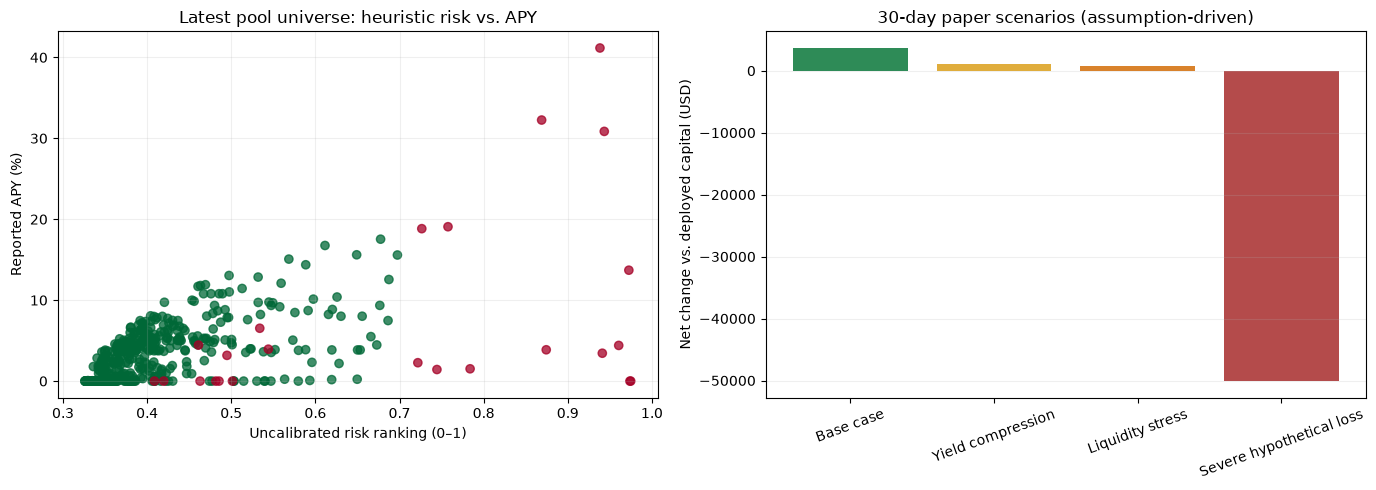

Pitch statement: a research prototype for screening yield opportunities with explicit risk gates, constrained paper allocation, and auditable what-if analysis.
Evidence caveat: this dataset has few matched incidents; current model scores are exploratory and must not be presented as reliable exploit prediction.


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(portfolio["risk_score"], portfolio["apy"], c=portfolio["eligible"].astype(int), cmap="RdYlGn", alpha=0.75)
axes[0].set_title("Latest pool universe: heuristic risk vs. APY")
axes[0].set_xlabel("Uncalibrated risk ranking (0–1)")
axes[0].set_ylabel("Reported APY (%)")
axes[0].grid(alpha=0.2)
axes[1].bar(scenarios["scenario"], scenarios["net_change_vs_deployed_usd"], color=["#2e8b57", "#e0ad3c", "#d9822b", "#b44b4b"])
axes[1].set_title("30-day paper scenarios (assumption-driven)")
axes[1].set_ylabel("Net change vs. deployed capital (USD)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

print("Pitch statement: a research prototype for screening yield opportunities with explicit risk gates, constrained paper allocation, and auditable what-if analysis.")
print("Evidence caveat: this dataset has few matched incidents; current model scores are exploratory and must not be presented as reliable exploit prediction.")

# 09 — End-to-end project quality checks

Run last. This notebook verifies artifacts, model environment, chronological holdout, risk-gated allocation, concentration caps, and the no-submission boundary. It reports every check and raises a clear assertion if a project invariant fails.

In [28]:
from pathlib import Path
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn

cwd = Path.cwd()
CODE_DIR = cwd if cwd.name == "code" else cwd / "code"
if not (CODE_DIR / "README.md").exists():
    CODE_DIR = cwd
DATA_DIR = CODE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
artifact_paths = {
    "features": PROCESSED_DIR / "features.csv",
    "hack_audit": PROCESSED_DIR / "hack_match_audit.csv",
    "predictions": PROCESSED_DIR / "test_predictions.csv",
    "risk_verdicts": PROCESSED_DIR / "paper_risk_verdicts.csv",
    "portfolio": PROCESSED_DIR / "portfolio_recommendations.csv",
    "move_ledger": PROCESSED_DIR / "paper_move_ledger.csv",
    "scenarios": PROCESSED_DIR / "paper_scenario_results.csv",
    "monitor": PROCESSED_DIR / "monitoring_report.csv",
    "feedback": PROCESSED_DIR / "human_feedback.csv",
    "bundle": DATA_DIR / "models" / "model_bundle.joblib",
}
missing_artifacts = [name for name, path in artifact_paths.items() if not path.exists()]
if missing_artifacts:
    raise FileNotFoundError("Run notebooks 01–08 first. Missing artifacts: " + ", ".join(missing_artifacts))

features = pd.read_csv(artifact_paths["features"], parse_dates=["timestamp"])
predictions = pd.read_csv(artifact_paths["predictions"])
verdicts = pd.read_csv(artifact_paths["risk_verdicts"])
portfolio = pd.read_csv(artifact_paths["portfolio"])
moves = pd.read_csv(artifact_paths["move_ledger"])
scenarios = pd.read_csv(artifact_paths["scenarios"])
monitor = pd.read_csv(artifact_paths["monitor"])
feedback = pd.read_csv(artifact_paths["feedback"])
bundle = joblib.load(artifact_paths["bundle"])
if bundle.get("model_schema_version") != 3:
    raise ValueError("Model schema is outdated; rerun notebooks 02–08 before quality checks.")
if bundle.get("scikit_learn_version") != sklearn.__version__:
    raise RuntimeError("Model and current scikit-learn versions differ; use the pinned environment and rerun notebook 02.")
if tuple(bundle.get("python_version", "").split(".")[:2]) != platform.python_version_tuple()[:2]:
    raise RuntimeError("Model and current Python minor versions differ; rerun notebook 02 in this environment.")

checks = []
def record_check(name, passed, details):
    checks.append({"check": name, "status": "PASS" if passed else "FAIL", "details": str(details)})


record_check("model_environment", True, f"Python {bundle['python_version']}; scikit-learn {bundle['scikit_learn_version']}")
record_check("features_nonempty", not features.empty, f"{len(features):,} rows")
record_check("feature_key_unique", not features.duplicated(["pool", "timestamp"]).any(), "pool + timestamp rows are unique")
record_check("binary_labels", features["label"].isin([0, 1]).all(), f"positive feature rows={int(features['label'].sum())}")
record_check("predictions_nonempty", not predictions.empty, f"{len(predictions):,} held-out rows")
record_check("predictions_binary_labels", predictions["label"].isin([0, 1]).all(), f"held-out positives={int(predictions['label'].sum())}")
if not predictions.empty:
    prediction_timestamps = pd.to_datetime(predictions["timestamp"], format="mixed", utc=True, errors="coerce")
    holdout_cutoff = pd.to_datetime(bundle["training_cutoff"], utc=True)
    timestamps_valid = prediction_timestamps.notna().all()
    chronological = timestamps_valid and prediction_timestamps.min() >= holdout_cutoff
    record_check("prediction_timestamps_valid", timestamps_valid, f"unparsed timestamps={int(prediction_timestamps.isna().sum())}")
    record_check("chronological_holdout", chronological, f"cutoff={holdout_cutoff}; first test={prediction_timestamps.min()}")
record_check("risk_verdicts_nonempty", not verdicts.empty, f"{len(verdicts)} pool verdicts")
budget = float(portfolio["capital_budget_usd"].iloc[0])
total_allocation = float(portfolio["allocation_usd"].sum())
record_check("portfolio_within_budget", total_allocation <= budget + 1e-6, f"${total_allocation:,.2f} allocated of ${budget:,.2f}")
pool_cap = float(portfolio["portfolio_weight"].max()) if not portfolio.empty else 0.0
record_check("pool_concentration_cap", pool_cap <= 0.150001, f"largest pool weight={pool_cap:.4f}")
protocol_weights = portfolio.groupby("project")["portfolio_weight"].sum()
protocol_cap = float(protocol_weights.max()) if not protocol_weights.empty else 0.0
record_check("protocol_concentration_cap", protocol_cap <= 0.250001, f"largest protocol weight={protocol_cap:.4f}")
allocated = portfolio.loc[portfolio["allocation_usd"] > 0]
record_check("only_allow_paper_allocated", allocated["eligible"].astype(bool).all(), f"allocated candidate count={len(allocated)}")
submitted_values = moves["submitted"].astype(str).str.lower().map({"true": True, "false": False})
record_check("no_submitted_transactions", submitted_values.notna().all() and not submitted_values.any(), "all move ledger rows must remain submitted=False")
scenario_values = scenarios[["projected_yield_usd", "paper_cost_usd", "ending_value_usd", "net_change_vs_deployed_usd"]].to_numpy(dtype=float)
record_check("scenario_outputs_finite", np.isfinite(scenario_values).all(), f"scenario count={len(scenarios)}")
record_check("monitor_outputs_present", not monitor.empty, f"monitor checks={len(monitor)}")
record_check("feedback_schema", {"feedback_id", "reviewed_outcome", "label_source", "verified_by"}.issubset(feedback.columns), f"review queue rows={len(feedback)}")

quality_report = pd.DataFrame(checks)
quality_path = PROCESSED_DIR / "project_quality_report.csv"
quality_report.to_csv(quality_path, index=False)
display(quality_report)
failures = quality_report.loc[quality_report["status"] == "FAIL"]
print(f"Quality checks: {len(checks) - len(failures)}/{len(checks)} passed. Report: {quality_path}")
if not failures.empty:
    raise AssertionError("Project invariant failure(s): " + "; ".join(failures["check"].tolist()))

,check,status,details
0,model_environment,PASS,Python 3.14.0; scikit-learn 1.9.1
1,features_nonempty,PASS,"301,305 rows"
2,feature_key_unique,PASS,pool + timestamp rows are unique
3,binary_labels,PASS,positive feature rows=665
4,predictions_nonempty,PASS,"94,684 held-out rows"
5,predictions_binary_labels,PASS,held-out positives=90
6,prediction_timestamps_valid,PASS,unparsed timestamps=0
7,chronological_holdout,PASS,cutoff=2026-04-21 21:01:32.569000+00:00; first...
8,risk_verdicts_nonempty,PASS,585 pool verdicts
9,portfolio_within_budget,PASS,"$1,000,000.00 allocated of $1,000,000.00"


Quality checks: 17/17 passed. Report: d:\python time\DeFi yield aggregator\attempt2\code\data\processed\project_quality_report.csv
